In [155]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

In [156]:
df = pd.read_csv('train.csv',usecols=['Age','Fare','Survived'])

In [157]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [158]:
df.isnull().mean() * 100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [159]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [160]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [161]:
X_train

,Age,Fare
30,40.0,27.7208
10,4.0,16.7000
873,47.0,9.0000
182,9.0,31.3875
876,20.0,9.8458
...,...,...
534,30.0,8.6625
584,NaN,8.7125
493,71.0,49.5042
527,NaN,221.7792


In [162]:
y_train

30     0
10     1
873    0
182    0
876    0
      ..
534    0
584    0
493    0
527    0
168    0
Name: Survived, Length: 712, dtype: int64

In [163]:
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']

In [164]:
X_test.tail()

,Age,Fare,Age_imputed
89,24.0,8.0500,24.0
80,22.0,9.0000,22.0
846,NaN,69.5500,NaN
870,26.0,7.8958,26.0
251,29.0,10.4625,29.0


In [165]:
X_train['Age_imputed'][X_train['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values
X_test['Age_imputed'][X_test['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_test['Age'].isnull().sum()).values

In [166]:
X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values

array([33. , 35. , 19. , 37. , 16. , 35. , 28. , 57. , 32. , 51. ,  1. ,
       27. , 30. , 25. , 30. , 14.5, 24. , 17. , 19. , 24. ,  4. , 30. ,
       24. , 70.5, 36. ,  2. , 16. , 60. , 45. , 34. , 47. , 27. , 14. ,
       34. , 27. , 41. , 21. , 22. , 28. , 38. ,  3. , 56. , 58. ,  9. ,
        8. , 33. , 21. , 31. , 52. , 30. , 30. , 39. , 58. , 48. ,  5. ,
       50. , 21. , 49. , 25. , 21. , 32. , 52. , 18. , 47. , 15. , 50. ,
       20. , 14. , 42. , 26. , 31. , 29. , 38. , 37. , 36. , 35. , 32. ,
       25. , 27. , 11. , 36. , 47. , 35. , 26. , 30. , 25. , 63. , 23. ,
       36. , 28. , 36. , 16. , 49. , 38. ,  2. , 20. , 44. , 34. , 19. ,
       16. , 29. , 10. , 62. , 33. , 36. , 23. , 32.5, 21. , 39. , 62. ,
       31. , 17. , 13. , 48. , 40. , 27. , 24. , 25. ,  9. , 31. , 35. ,
       30. , 36. , 21. , 26. , 18. , 47. , 20. , 35. , 41. , 62. , 34. ,
       29. , 32. , 65. , 16. , 41. , 21. , 23. , 28. , 24. , 17. , 39. ,
       32. , 32. , 29. , 37. , 31. ])

In [167]:
X_train['Age'].isnull().sum()

np.int64(148)

In [168]:
X_train

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,24.0
493,71.0,49.5042,71.0
527,NaN,221.7792,4.0


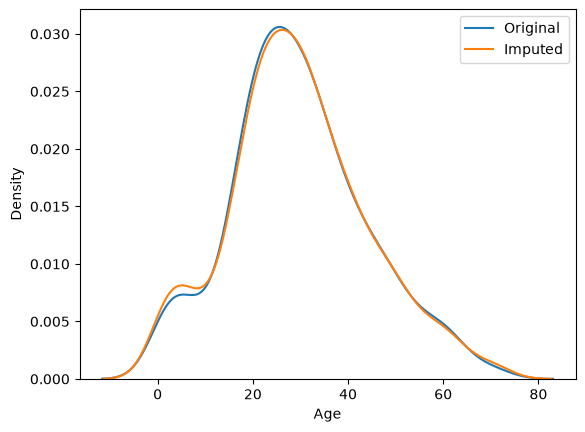

In [169]:
sns.kdeplot(X_train['Age'], label='Original')
sns.kdeplot(X_train['Age_imputed'], label='Imputed')

plt.legend()
plt.show()

In [170]:
print('Original variable variance: ', X_train['Age'].var())
print('Variance after random imputation: ', X_train['Age_imputed'].var())

Original variable variance:  204.34951339046142
Variance after random imputation:  211.58546981443288


In [171]:
X_train[['Fare', 'Age', 'Age_imputed']].cov()

,Fare,Age,Age_imputed
Fare,2368.246832,71.512440,52.693433
Age,71.512440,204.349513,204.349513
Age_imputed,52.693433,204.349513,211.585470


<Axes: >

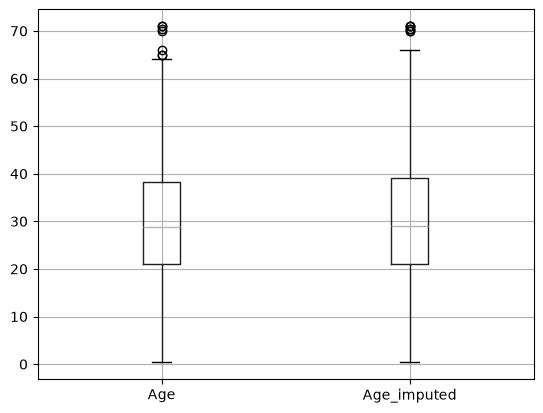

In [172]:
X_train[['Age', 'Age_imputed']].boxplot()

In [173]:
observation = X_train.iloc[0]

sampled_value = X_train['Age'].dropna().sample(1, random_state=int(observation['Fare']))

In [174]:
data = pd.read_csv('house-train.csv',usecols=['GarageQual','FireplaceQu', 'SalePrice'])

In [175]:
data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [176]:
data.isnull().mean() * 100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [177]:
X = data
y = data['SalePrice']

In [178]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [179]:
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

X_train['FireplaceQu_imputed'] = X_train['FireplaceQu']
X_test['FireplaceQu_imputed'] = X_test['FireplaceQu']

In [180]:
X_train.sample(5)

,FireplaceQu,GarageQual,SalePrice,GarageQual_imputed,FireplaceQu_imputed
566,Gd,TA,325000,TA,Gd
3,Gd,TA,140000,TA,Gd
986,NaN,Fa,117000,Fa,NaN
453,NaN,TA,210000,TA,NaN
303,NaN,TA,149900,TA,NaN


In [181]:
X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_train['GarageQual'].isnull().sum()).values
X_test['GarageQual_imputed'][X_test['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_test['GarageQual'].isnull().sum()).values

X_train['FireplaceQu_imputed'][X_train['FireplaceQu_imputed'].isnull()] = X_train['FireplaceQu'].dropna().sample(X_train['FireplaceQu'].isnull().sum()).values
X_test['FireplaceQu_imputed'][X_test['FireplaceQu_imputed'].isnull()] = X_train['FireplaceQu'].dropna().sample(X_test['FireplaceQu'].isnull().sum()).values

C:\Users\kumar\AppData\Local\Temp\ipykernel_12844\856878696.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_train['GarageQual'].isnull().sum()).values
C:\Users\kumar\AppData\Local\Temp\ipykernel_12844\856878696.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_test['GarageQual_imputed'][X_test['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_test['GarageQual'].isnull().sum()).values
C:\Users\kumar\AppData\Local\Temp\ipykernel_12844\856878696.py:4: SettingWithCopyWarning: 
A va

In [182]:
temp = pd.concat(
        [
            X_train['GarageQual'].value_counts() / len(X_train['GarageQual'].dropna()),
            X_train['GarageQual_imputed'].value_counts() / len(X_train)
        ],
        axis=1)

temp.columns = ['original', 'imputed']

In [183]:
temp

,original,imputed
TA,0.951043,0.949486
Fa,0.037171,0.037671
Gd,0.009973,0.011130
Po,0.000907,0.000856
Ex,0.000907,0.000856


In [184]:
temp = pd.concat(
        [
            X_train['FireplaceQu'].value_counts() / len(X_train['FireplaceQu'].dropna()),
            X_train['FireplaceQu_imputed'].value_counts() / len(df)
        ],
        axis=1)

temp.columns = ['original', 'imputed']

temp

,original,imputed
Gd,0.494272,0.649832
TA,0.412439,0.537598
Fa,0.040917,0.054994
Po,0.027823,0.035915
Ex,0.024550,0.032548


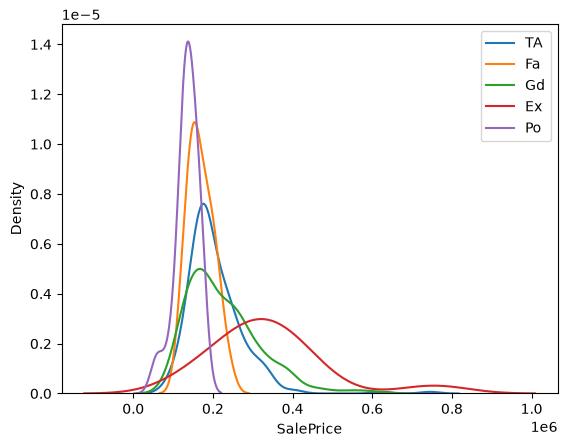

In [185]:
for category in X_train['FireplaceQu'].dropna().unique():
    sns.kdeplot(
        X_train[X_train['FireplaceQu'] == category]['SalePrice'],
        label=category
    )

plt.legend()
plt.show()

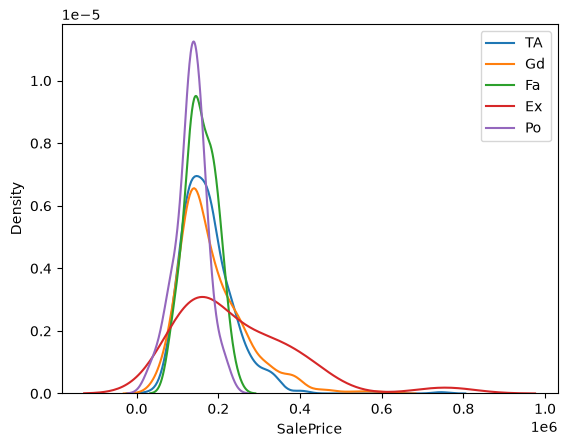

In [186]:
for category in X_train['FireplaceQu_imputed'].dropna().unique():
    sns.kdeplot(
        X_train[X_train['FireplaceQu_imputed'] == category]['SalePrice'],
        label=category
    )

plt.legend()
plt.show()